<center><h1>Tong_Stephanie_HW4</h1></center>
<br>
<br>

Name: Stephanie Tong
<br>
Github Username: tongstep
<br>
USC ID: 2614015757

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from scipy.stats import bootstrap

Get the AReM Data Set

In [2]:
import os

data_path = "AReM"

print(os.listdir(data_path))

['bendingType.pdf', '.DS_Store', 'bending1', 'walking', 'sensorsPlacement.pdf', 'bending2', 'standing', 'sitting', 'lying', 'cycling']


In [3]:
file_path = os.path.join(data_path, "bending1", "dataset1.csv")

columns = ["time", "avg_rss12", "var_rss12",
           "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

df = pd.read_csv(file_path, skiprows=5, header=None, names=columns)

print(df.head())
print(df.shape)
print(df.columns)

   time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  var_rss23
0     0      39.25       0.43      22.75       0.43      33.75        1.3
1   250      39.25       0.43      23.00       0.00      33.00        0.0
2   500      39.25       0.43      23.25       0.43      33.00        0.0
3   750      39.50       0.50      23.00       0.71      33.00        0.0
4  1000      39.50       0.50      24.00       0.00      33.00        0.0
(480, 7)
Index(['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23',
       'var_rss23'],
      dtype='object')


### (b) Splitting Data

In [4]:
activities = ["bending1", "bending2", "cycling", "lying",
              "sitting", "standing", "walking"]

test_data = []
train_data = []

for activity in activities:
    folder_path = os.path.join(data_path, activity)

    for filename in os.listdir(folder_path):
        if filename.endswith(".csv"):
            dataset_num = int(filename.replace("dataset", "").replace(".csv", ""))

            if activity in ["bending1", "bending2"]:
                if dataset_num <= 2:
                    test_data.append((activity, filename))
                else:
                    train_data.append((activity, filename))
            else:
                if dataset_num <= 3:
                    test_data.append((activity, filename))
                else:
                    train_data.append((activity, filename))

print("Number of training files:", len(train_data))
print("Number of testing files:", len(test_data))

Number of training files: 69
Number of testing files: 19


### (c) Feature Extraction

In [5]:
def extract(activity, filename):
    file_path = os.path.join(data_path, activity, filename)

    try:
        df = pd.read_csv(file_path, skiprows=5, header=None, names=columns)

        if df["avg_rss12"].isna().any():
            df = pd.read_csv(file_path, skiprows=5, header=None,
                             sep=r"\s+", names=columns)
    except:
        df = pd.read_csv(file_path, skiprows=5, header=None,
                         sep=r"\s+", names=columns)

    features = []
    for col in columns[1:]:
        features.extend([
            df[col].min(),
            df[col].max(),
            df[col].mean(),
            df[col].median(),
            df[col].std(),
            df[col].quantile(0.25),
            df[col].quantile(0.75)
        ])

    return features

def sort_files(x):
    activity = x[0]
    dataset_number = int(x[1].replace("dataset", "").replace(".csv", ""))
    return (activity, dataset_number)

all_files = sorted(train_data + test_data, key=sort_files)

all_features = []

for activity, filename in all_files:
    all_features.append(extract(activity, filename))

feature_names = ["min", "max", "mean", "median", "std", "1st quartile", "3rd quartile"]
column_names = [
    name + str(i)
    for i in range(1, 7)
    for name in feature_names
]

feature_table = pd.DataFrame(all_features, columns=column_names)
feature_table.insert(0, "Instance", range(1, len(feature_table) + 1))

feature_table

,Instance,min1,max1,mean1,median1,std1,1st quartile1,3rd quartile1,min2,max2,...,std5,1st quartile5,3rd quartile5,min6,max6,mean6,median6,std6,1st quartile6,3rd quartile6
0,1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
1,2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
2,3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
3,4,33.00,47.75,42.179813,43.50,3.670666,39.15,45.0000,0.0,3.00,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
4,5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
84,85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,...,3.119856,13.5000,17.75,0.00,9.67,3.432562,3.20,1.732727,2.1575,4.5650
85,86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350
86,87,23.50,46.25,34.873229,35.25,4.531720,31.75,38.2500,0.0,14.82,...,3.131076,13.7500,18.00,0.00,9.51,3.424646,3.27,1.690960,2.1700,4.5000


In [6]:
def stdev(x, axis=-1):
    return np.std(x, axis=axis, ddof=1)

feature_columns = feature_table.columns[1:]
results = []

for col in feature_columns:
    values = feature_table[col].to_numpy()

    std = np.std(values, ddof=1)

    result = bootstrap(
        (values,),
        stdev,
        confidence_level=0.9,
        method="basic",
        n_resamples=1000,
        random_state=42
    )

    results.append([
        col,
        std,
        result.confidence_interval.low,
        result.confidence_interval.high
    ])

std_results = pd.DataFrame(
    results,
    columns=["Feature", "Standard Deviation", "90% CI Lower", "90% CI Upper"]
)

std_results

,Feature,Standard Deviation,90% CI Lower,90% CI Upper
0,min1,9.569975,8.447284,10.872543
1,max1,4.394362,3.500763,5.454666
2,mean1,5.335718,4.768721,6.002839
3,median1,5.440054,4.862233,6.120846
4,std1,1.772153,1.598435,1.972583
5,1st quartile1,6.153590,5.656649,6.769293
6,3rd quartile1,5.138925,4.418667,6.002306
7,min2,0.000000,0.000000,0.000000
8,max2,5.062729,4.719163,5.495995
9,mean2,1.574164,1.442088,1.745883


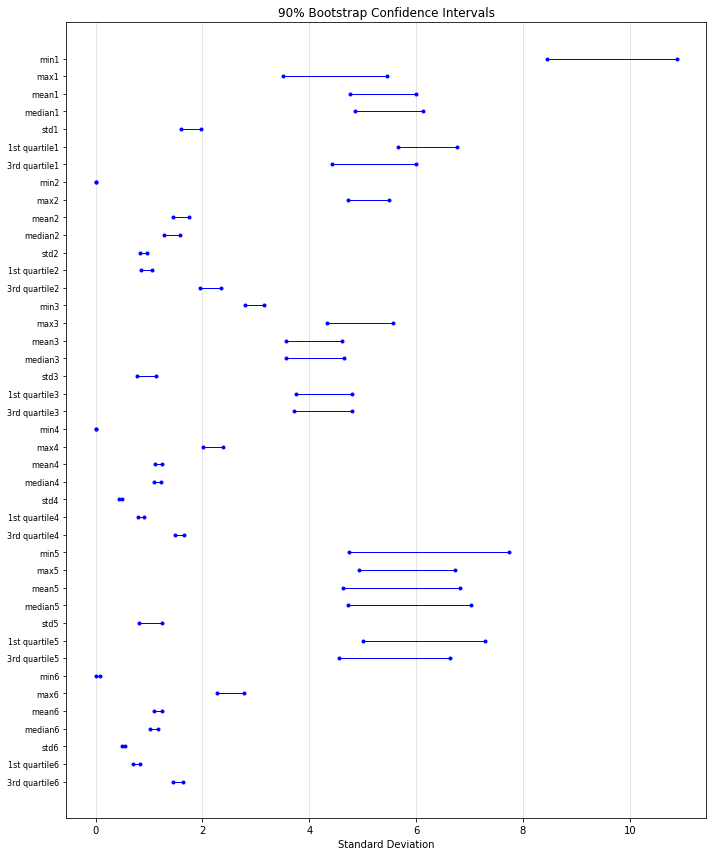

In [7]:
plt.figure(figsize=(10, 12))

for i in range(len(std_results)):
    plt.plot(
        [std_results["90% CI Lower"][i],
         std_results["90% CI Upper"][i]],
        [i, i],
        "o-",
        color="blue",
        linewidth=1,
        markersize=3
    )

plt.yticks(range(len(std_results)), std_results["Feature"], fontsize=8)
plt.gca().invert_yaxis()
plt.xlabel("Standard Deviation")
plt.title("90% Bootstrap Confidence Intervals")
plt.grid(axis="x", alpha=0.4)
plt.tight_layout()
plt.show()

I selected the minimum, mean, and maximum. The minimum and maximum show the lowest and highest sensor readings, while the mean shows the average reading. These summarize the range and average level of the sensor data, which can help describe differences between activities.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

In [8]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from pandas.plotting import scatter_matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.feature_selection import RFE
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score
from sklearn.utils import resample
from sklearn.model_selection import cross_val_score
from sklearn.utils import resample
from sklearn.preprocessing import label_binarize
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler

import seaborn as sns

warnings.filterwarnings("ignore")

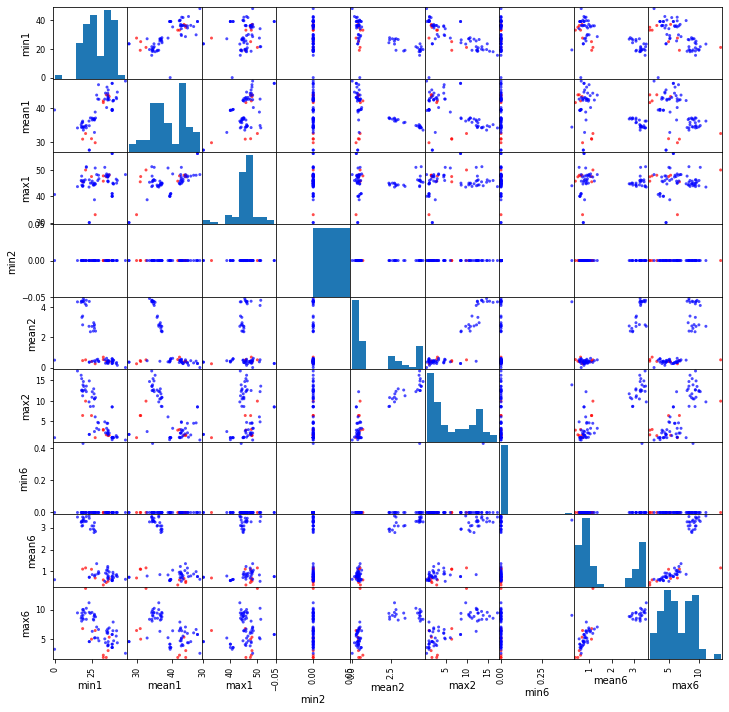

In [9]:
plot_data = feature_table.copy()
plot_data["Activity"] = [activity for activity, filename in all_files]

classes = []

for activity in plot_data["Activity"]:
    if activity in ["bending1", "bending2"]:
        classes.append("Bending")
    else:
        classes.append("Other")

plot_data["Class"] = classes

train_rows = []

for i, file in enumerate(all_files):
    if file in train_data:
        train_rows.append(i)

train_plot_data = plot_data.iloc[train_rows].copy()

plot_features = ["min1", "mean1", "max1",
                 "min2", "mean2", "max2",
                 "min6", "mean6", "max6"]

colors = train_plot_data["Class"].map(
    {"Bending": "red", "Other": "blue"}
)

scatter_matrix(
    train_plot_data[plot_features],
    figsize=(12, 12),
    diagonal="hist",
    color=colors,
    alpha=0.7
)

plt.show()


#### ii. Splitted Plots

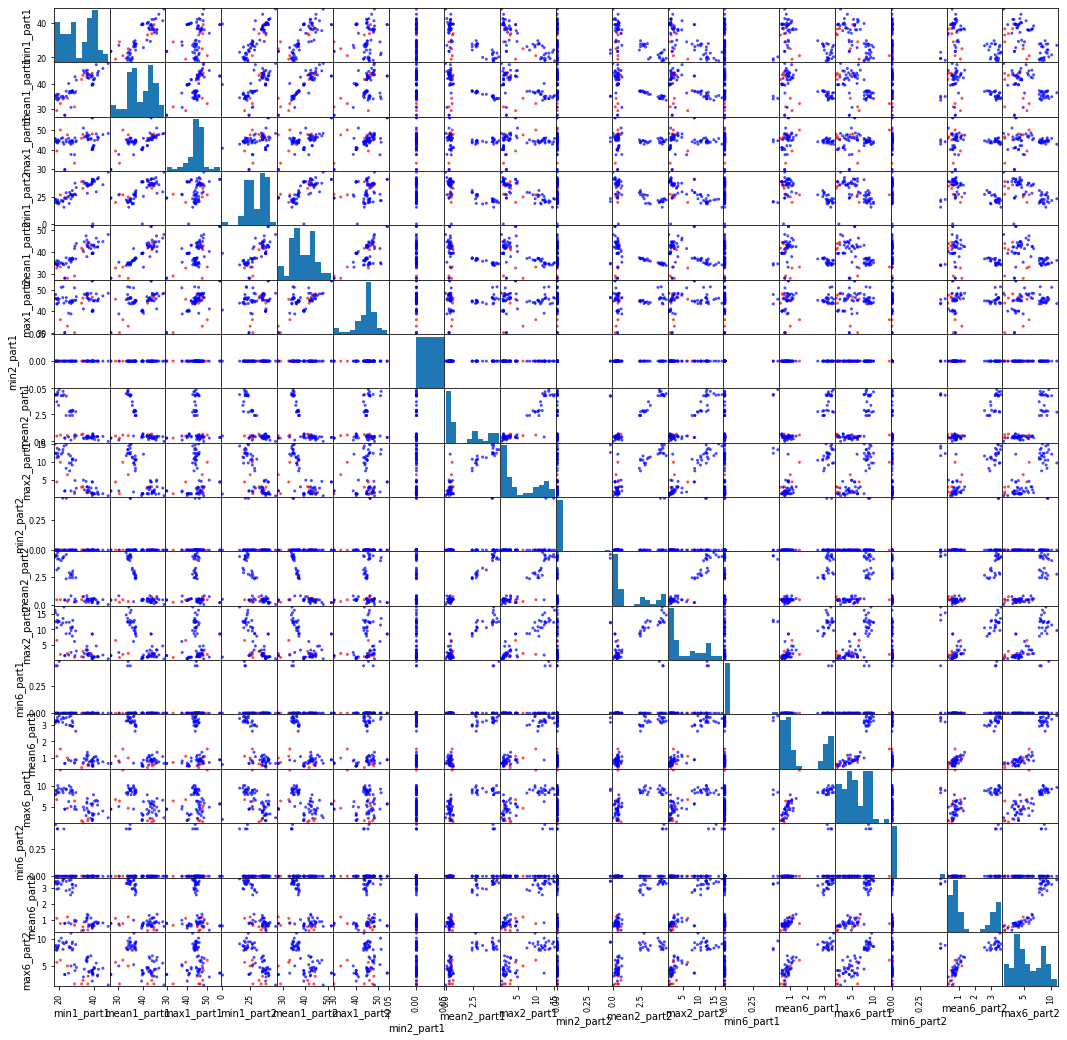

In [10]:
split_features = []
split_classes = []

for activity, filename in train_data:
    file_path = os.path.join(data_path, activity, filename)

    try:
        df = pd.read_csv(file_path, skiprows=5, header=None, names=columns)
        if df["avg_rss12"].isna().any():
            df = pd.read_csv(file_path, skiprows=5, header=None,
                             sep=r"\s+", names=columns)
    except:
        df = pd.read_csv(file_path, skiprows=5, header=None,
                         sep=r"\s+", names=columns)

    middle = len(df) // 2
    first_half = df.iloc[:middle]
    second_half = df.iloc[middle:]

    row_features = []

    for col in ["avg_rss12", "var_rss12", "var_rss23"]:
        for part in [first_half, second_half]:
            row_features.extend([
                part[col].min(),
                part[col].mean(),
                part[col].max()
            ])

    split_features.append(row_features)

    if activity in ["bending1", "bending2"]:
        split_classes.append("Bending")
    else:
        split_classes.append("Other")

split_columns = [
    name + str(series) + "_part" + str(part)
    for series in [1, 2, 6]
    for part in [1, 2]
    for name in ["min", "mean", "max"]
]

split_table = pd.DataFrame(split_features, columns=split_columns)
split_table["Class"] = split_classes

plot_columns = split_columns

plot_colors = split_table["Class"].map(
    {"Bending": "red", "Other": "blue"}
)

scatter_matrix(
    split_table[plot_columns],
    figsize=(18, 18),
    diagonal="hist",
    color=plot_colors,
    alpha=0.7
)

plt.show()

Compared with part (i), the plots look generally similar after splitting each time series into two halves. 

#### iii. Time Series Segments

In [11]:
def extract_segment_features(activity, filename, l):
    file_path = os.path.join(data_path, activity, filename)

    try:
        df = pd.read_csv(file_path, skiprows=5, header=None, names=columns)
        if df["avg_rss12"].isna().any():
            df = pd.read_csv(file_path, skiprows=5, header=None,
                             sep=r"\s+", names=columns)
    except:
        df = pd.read_csv(file_path, skiprows=5, header=None,
                         sep=r"\s+", names=columns)

    features = []

    for part in np.array_split(df, l):
        for col in columns[1:]:
            features.extend([
                part[col].min(),
                part[col].max(),
                part[col].mean(),
                part[col].median(),
                part[col].std(),
                part[col].quantile(0.25),
                part[col].quantile(0.75)
            ])

    return features


In [12]:
train_classes = []

for activity, filename in train_data:
    if activity in ["bending1", "bending2"]:
        train_classes.append("Bending")
    else:
        train_classes.append("Other")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

cv_results = []

for l in range(1, 21):
    train_segment_features = []

    for activity, filename in train_data:
        features = extract_segment_features(activity, filename, l)
        train_segment_features.append(features)

    X = np.array(train_segment_features)
    y = np.array(train_classes)

    for p in range(1, 11):
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("selection", RFE(
                LogisticRegression(C=1e6, max_iter=1000, solver="liblinear"),
                n_features_to_select=p,
                step=0.2
            )),
            ("logistic", LogisticRegression(
                C=1e6, max_iter=1000, solver="liblinear"
            ))
        ])

        scores = cross_val_score(
            model, X, y, cv=cv, scoring="accuracy"
        )

        cv_results.append([l, p, scores.mean()])

cv_table = pd.DataFrame(
    cv_results,
    columns=["l", "p", "CV Accuracy"]
)

cv_table = cv_table.sort_values(
    "CV Accuracy", ascending=False
).reset_index(drop=True)

print(cv_table.head(10))

best_l = int(cv_table.iloc[0]["l"])
best_p = int(cv_table.iloc[0]["p"])
best_accuracy = cv_table.iloc[0]["CV Accuracy"]

print("Best l:", best_l)
print("Best p:", best_p)
print("Best CV accuracy:", best_accuracy)


    l   p  CV Accuracy
0   1   6     0.985714
1   1   2     0.971429
2   1   4     0.971429
3   1   7     0.971429
4   2   3     0.971429
5  14   1     0.970330
6   1   5     0.970330
7   3  10     0.957143
8  19  10     0.957143
9  19   9     0.957143
Best l: 1
Best p: 6
Best CV accuracy: 0.9857142857142858


I used 5-fold cross-validation to compare different values of (l) (1 to 20) and (p) (1 to 10). The best combination was (l = 1) and (p = 6), with an average CV accuracy of 98.57%. This means that using the original time series and six selected features gave the highest accuracy among the combinations tested.

The right way to do cross-validation is to split the training data into 5 folds and select the features separately for each fold, using only its training portion. The model is tested on the fold that was left out, and this is repeated for all 5 folds. The average accuracy is then calculated.

The wrong way is to select the features using the entire training dataset first and then perform cross-validation. This is because the validation data has already influenced which features are selected, so the accuracy may look better than it actually is. Feature selection should be done separately within each fold.

#### iv. Confusion Matrix

Confusion Matrix:
[[60  0]
 [ 0  9]]
Training Accuracy: 1.0
Training AUC: 1.0


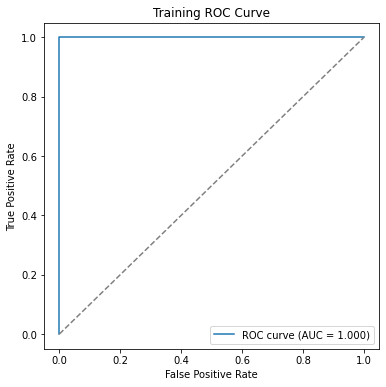

Intercept: -17.72861322982658
Selected feature coefficients:
Feature 1 : -5.739087284576419
Feature 2 : 4.263743194148143
Feature 3 : -3.4736488858127914
Feature 4 : 10.358186497934932
Feature 5 : 7.249378758106543
Feature 6 : -6.666865081847678


In [13]:
X_best = []

for activity, filename in train_data:
    features = extract_segment_features(activity, filename, best_l)
    X_best.append(features)

X_best = np.array(X_best)

y_binary = np.array([
    1 if activity in ["bending1", "bending2"] else 0
    for activity, filename in train_data
])

best_model = Pipeline([
    ("scaler", StandardScaler()),
    ("selection", RFE(
        LogisticRegression(C=1e6, max_iter=100, solver="liblinear"),
        n_features_to_select=best_p,
        step=0.2
    )),
    ("logistic", LogisticRegression(
        C=1e6, max_iter=1000, solver="liblinear"
    ))
])

best_model.fit(X_best, y_binary)

train_predictions = best_model.predict(X_best)
train_probabilities = best_model.predict_proba(X_best)[:, 1]

cm = confusion_matrix(y_binary, train_predictions)
train_accuracy = accuracy_score(y_binary, train_predictions)
train_auc = roc_auc_score(y_binary, train_probabilities)

print("Confusion Matrix:")
print(cm)
print("Training Accuracy:", train_accuracy)
print("Training AUC:", train_auc)

fpr, tpr, thresholds = roc_curve(y_binary, train_probabilities)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label="ROC curve (AUC = {:.3f})".format(train_auc))
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curve")
plt.legend()
plt.show()

selected_features = best_model.named_steps["selection"].support_
coefficients = best_model.named_steps["logistic"].coef_[0]

print("Intercept:", best_model.named_steps["logistic"].intercept_[0])
print("Selected feature coefficients:")

for i, coefficient in enumerate(coefficients):
    print("Feature", i + 1, ":", coefficient)

In [14]:
X_scaled = best_model.named_steps["scaler"].transform(X_best)

selected_features = best_model.named_steps["selection"].get_support()

X_selected = X_scaled[:, selected_features]
X_selected = sm.add_constant(X_selected)

logit_model = sm.Logit(y_binary, X_selected).fit(
    method="bfgs", maxiter=5000, disp=0
)

print(logit_model.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       62
Method:                           MLE   Df Model:                            6
Date:                Sun, 18 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        21:40:17   Log-Likelihood:            -0.00051118
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 9.592e-10
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -26.0090   4611.555     -0.006      0.995   -9064.490    9012.472
x1            -6.7961   1268.807     -0.005      0.996   -2493.613    2480.020
x2             1.8810   2775.155      0.001      0.9

The confusion matrix was [[60, 0], [0, 9]], with a training accuracy of 100%. The AUC was 1.000. This indicates that the classifier perfectly distinguished Bending from Other on the training data.

The logistic regression intercept was (\beta_0 = -17.7286). The six selected feature coefficients were (B1 = -5.7391), (B2 = 4.2637), (B3 = -3.4736), (B4 = 10.3582), (B5 = 7.2494), and (B6 = -6.6669). B1 indicates beta 1, etc.

The statsmodels model showed a quasi-separation warning, so the p-values may not be reliable.

#### v. Test Classifier

In [15]:
X_test = []
y_test = []

for activity, filename in test_data:
    features = extract_segment_features(activity, filename, best_l)
    X_test.append(features)

    if activity in ["bending1", "bending2"]:
        y_test.append(1)
    else:
        y_test.append(0)

X_test = np.array(X_test)
y_test = np.array(y_test)

test_predictions = best_model.predict(X_test)

test_cm = confusion_matrix(y_test, test_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

print("Test Confusion Matrix:")
print(test_cm)
print("Test Accuracy:", test_accuracy)
print("Cross-validation Accuracy:", best_accuracy)

Test Confusion Matrix:
[[15  0]
 [ 0  4]]
Test Accuracy: 1.0
Cross-validation Accuracy: 0.9857142857142858


The test accuracy was 100%, compared with the average 5-fold cross-validation accuracy of 98.57%. The test accuracy was slightly higher than the cross-validation accuracy. The classifier correctly classified all 15 Other instances and all 4 Bending instances in the test set.

#### vi. Separation

The two classes were clearly separated by the selected features, resulting in perfect training accuracy. However, the quasi-separation warning and large standard errors suggest that the coefficient estimates and p-values may be unreliable.

#### vii. Imbalance

The training data is imbalanced, with 60 Other instances and 9 Bending instances.

Test Confusion Matrix:
[[15  0]
 [ 0  4]]
Test AUC: 1.0


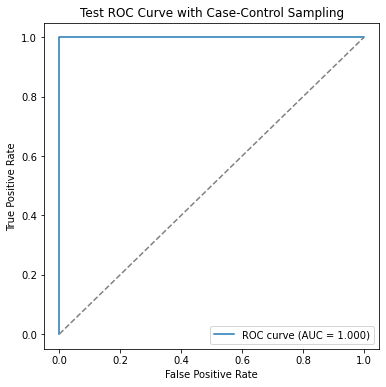

In [16]:
bending_indices = np.where(y_binary == 1)[0]
other_indices = np.where(y_binary == 0)[0]

np.random.seed(1)
sampled_other_indices = np.random.choice(
    other_indices, size=len(bending_indices), replace=False
)

sampled_indices = np.concatenate([
    bending_indices, sampled_other_indices
])

X_sampled = X_best[sampled_indices]
y_sampled = y_binary[sampled_indices]

balanced_model = Pipeline([
    ("scaler", StandardScaler()),
    ("selection", RFE(
        LogisticRegression(max_iter=100, solver="liblinear"),
        n_features_to_select=best_p,
        step=0.2
    )),
    ("logistic", LogisticRegression(
        max_iter=100, solver="liblinear"
    ))
])

balanced_model.fit(X_sampled, y_sampled)

original_ratio = len(bending_indices) / len(other_indices)
adjustment = np.log(original_ratio)

balanced_model.named_steps["logistic"].intercept_ += adjustment

test_predictions_balanced = balanced_model.predict(X_test)
test_probabilities_balanced = balanced_model.predict_proba(X_test)[:, 1]

cm_balanced = confusion_matrix(y_test, test_predictions_balanced)
auc_balanced = roc_auc_score(y_test, test_probabilities_balanced)

print("Test Confusion Matrix:")
print(cm_balanced)
print("Test AUC:", auc_balanced)

fpr_balanced, tpr_balanced, thresholds_balanced = roc_curve(
    y_test, test_probabilities_balanced
)

plt.figure(figsize=(6, 6))
plt.plot(fpr_balanced, tpr_balanced,
         label="ROC curve (AUC = {:.3f})".format(auc_balanced))
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC Curve with Case-Control Sampling")
plt.legend()
plt.show()

The training data was imablanced, with 60 Other instances and 9 Bending instances. After case-control sampling and adjusting the logistic regression intercept, the model achieved a test AUC of 1.000 and correctly classified all 19 test instances.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [17]:
l_values = range(1, 21)
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

best_l1_accuracy = 0

for l in l_values:
    X = []

    for activity, filename in train_data:
        features = extract_segment_features(activity, filename, l)
        X.append(features)

    X = np.array(X)

    for C in C_values:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("logistic", LogisticRegression(
                penalty="l1",
                C=C,
                solver="liblinear",
                max_iter=100
            ))
        ])

        scores = cross_val_score(
            model, X, y_binary, cv=cv, scoring="accuracy"
        )

        mean_accuracy = np.mean(scores)

        if mean_accuracy > best_l1_accuracy:
            best_l1_accuracy = mean_accuracy
            best_l_l1 = l
            best_C = C

print("Best l:", best_l_l1)
print("Best C:", best_C)
print("Best 5-fold CV accuracy:", best_l1_accuracy)

X_l1 = []
X_test_l1 = []

for activity, filename in train_data:
    X_l1.append(extract_segment_features(activity, filename, best_l_l1))

for activity, filename in test_data:
    X_test_l1.append(extract_segment_features(activity, filename, best_l_l1))

X_l1 = np.array(X_l1)
X_test_l1 = np.array(X_test_l1)

l1_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l1",
        C=best_C,
        solver="liblinear",
        max_iter=100
    ))
])

l1_model.fit(X_l1, y_binary)

l1_train_predictions = l1_model.predict(X_l1)

print("L1 training confusion matrix:")
print(confusion_matrix(y_binary, l1_train_predictions))
print("L1 training accuracy:", accuracy_score(y_binary, l1_train_predictions))


Best l: 12
Best C: 1
Best 5-fold CV accuracy: 0.9857142857142858
L1 training confusion matrix:
[[60  0]
 [ 0  9]]
L1 training accuracy: 1.0


Using L1-penalized logistic regression with 5-fold cross-validation, the best combination was l = 12 and C = 1, with an average CV accuracy of 98.57%. The model achieved 100% training accuracy, with a confusion matrix of [[60, 0], [0, 9]].

#### ii. Comparison

In [18]:

l_values = range(1, 21)
pvalue_scores = []

for l in l_values:
    X = []

    for activity, filename in train_data:
        features = extract_segment_features(activity, filename, l)
        X.append(features)

    X = np.array(X)
    fold_scores = []

    for train_index, val_index in cv.split(X, y_binary):
        X_train_fold = X[train_index]
        X_val_fold = X[val_index]
        y_train_fold = y_binary[train_index]
        y_val_fold = y_binary[val_index]

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train_fold)
        X_val_scaled = scaler.transform(X_val_fold)

        p_values = []

        for j in range(X_train_scaled.shape[1]):
            X_one = sm.add_constant(X_train_scaled[:, j])

            try:
                result = sm.Logit(y_train_fold, X_one).fit(
                    disp=0, method="bfgs", maxiter=100
                )
                p_values.append(result.pvalues[1])
            except:
                p_values.append(np.nan)

        selected = [
            j for j, p in enumerate(p_values)
            if not np.isnan(p) and p < 0.05
        ]

        if len(selected) == 0:
            valid_pvalues = [
                (j, p) for j, p in enumerate(p_values)
                if not np.isnan(p)
            ]
            if len(valid_pvalues) == 0:
                selected = list(range(X_train_scaled.shape[1]))
            else:
                selected = [min(valid_pvalues, key=lambda item: item[1])[0]]

        model = LogisticRegression(
            solver="liblinear", max_iter=100
        )
        model.fit(X_train_scaled[:, selected], y_train_fold)
        predictions = model.predict(X_val_scaled[:, selected])

        fold_scores.append(
            accuracy_score(y_val_fold, predictions)
        )

    pvalue_scores.append(np.mean(fold_scores))

best_l_pvalue = list(l_values)[np.argmax(pvalue_scores)]
best_accuracy_pvalue = max(pvalue_scores)

print("Best l for p-value selection:", best_l_pvalue)
print("Best 5-fold CV accuracy for p-value selection:", best_accuracy_pvalue)

X_pvalue_train = []
X_pvalue_test = []

for activity, filename in train_data:
    X_pvalue_train.append(
        extract_segment_features(activity, filename, best_l_pvalue)
    )

for activity, filename in test_data:
    X_pvalue_test.append(
        extract_segment_features(activity, filename, best_l_pvalue)
    )

X_pvalue_train = np.array(X_pvalue_train)
X_pvalue_test = np.array(X_pvalue_test)

scaler = StandardScaler()
X_pvalue_train_scaled = scaler.fit_transform(X_pvalue_train)
X_pvalue_test_scaled = scaler.transform(X_pvalue_test)

p_values = []

for j in range(X_pvalue_train_scaled.shape[1]):
    X_one = sm.add_constant(X_pvalue_train_scaled[:, j])

    try:
        result = sm.Logit(y_binary, X_one).fit(
            disp=0, method="bfgs", maxiter=100
        )
        p_values.append(result.pvalues[1])
    except:
        p_values.append(np.nan)

selected = [
    j for j, p in enumerate(p_values)
    if not np.isnan(p) and p < 0.05
]

if len(selected) == 0:
    valid_pvalues = [
        (j, p) for j, p in enumerate(p_values)
        if not np.isnan(p)
    ]
    if len(valid_pvalues) == 0:
        selected = list(range(X_pvalue_train_scaled.shape[1]))
    else:
        selected = [min(valid_pvalues, key=lambda item: item[1])[0]]

pvalue_classifier = LogisticRegression(
    solver="liblinear", max_iter=100
)
pvalue_classifier.fit(X_pvalue_train_scaled[:, selected], y_binary)

pvalue_predictions = pvalue_classifier.predict(
    X_pvalue_test_scaled[:, selected]
)

print("Number of selected features:", len(selected))
print("P-value model test confusion matrix:")
print(confusion_matrix(y_test, pvalue_predictions))
print("P-value model test accuracy:", accuracy_score(y_test, pvalue_predictions))

l1_test_predictions = l1_model.predict(X_test_l1)

print("L1 model test confusion matrix:")
print(confusion_matrix(y_test, l1_test_predictions))
print("L1 model test accuracy:", accuracy_score(y_test, l1_test_predictions))


Best l for p-value selection: 6
Best 5-fold CV accuracy for p-value selection: 0.9714285714285715
Number of selected features: 60
P-value model test confusion matrix:
[[15  0]
 [ 0  4]]
P-value model test accuracy: 1.0
L1 model test confusion matrix:
[[15  0]
 [ 1  3]]
L1 model test accuracy: 0.9473684210526315


L1-penalized logistic regression achieved a higher 5-fold cross-validation accuracy of 98.57%, compared with 97.14% for p-value-based feature selection. However, p-value-based selection achieved a higher test accuracy of 100%, compared with 94.74% for L1 regularization. L1-penalized logistic regression was easier to implement because it performs feature selection automatically through regularization, while the p-value method requires calculating p-values and selecting features separately.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [19]:
y_train_multi = np.array([activity for activity, filename in train_data])
y_test_multi = np.array([activity for activity, filename in test_data])

In [20]:
l_values = range(1, 21)
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

best_multi_accuracy = 0

for l in l_values:
    X = []

    for activity, filename in train_data:
        features = extract_segment_features(activity, filename, l)
        X.append(features)

    X = np.array(X)

    for C in C_values:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("logistic", LogisticRegression(
                penalty="l1",
                C=C,
                solver="saga",
                max_iter=100
            ))
        ])

        scores = cross_val_score(
            model, X, y_train_multi, cv=cv, scoring="accuracy"
        )

        mean_accuracy = np.mean(scores)

        if mean_accuracy > best_multi_accuracy:
            best_multi_accuracy = mean_accuracy
            best_l_multi = l
            best_C_multi = C

print("Best l:", best_l_multi)
print("Best C:", best_C_multi)
print("Best 5-fold CV accuracy:", best_multi_accuracy)

Best l: 1
Best C: 10
Best 5-fold CV accuracy: 0.8978021978021978


In [21]:
X_train_multi = []
X_test_multi = []

for activity, filename in train_data:
    X_train_multi.append(extract_segment_features(activity, filename, best_l_multi))

for activity, filename in test_data:
    X_test_multi.append(extract_segment_features(activity, filename, best_l_multi))

X_train_multi = np.array(X_train_multi)
X_test_multi = np.array(X_test_multi)

multi_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty="l1",
        C=best_C_multi,
        solver="saga",
        max_iter=100
    ))
])

multi_model.fit(X_train_multi, y_train_multi)

multi_predictions = multi_model.predict(X_test_multi)

print("Test accuracy:", accuracy_score(y_test_multi, multi_predictions))
print("Test error:", 1 - accuracy_score(y_test_multi, multi_predictions))
print("Confusion matrix:")
print(confusion_matrix(y_test_multi, multi_predictions, labels=activities))

Test accuracy: 0.8947368421052632
Test error: 0.10526315789473684
Confusion matrix:
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 1 0 2 0]
 [0 0 0 0 0 0 3]]


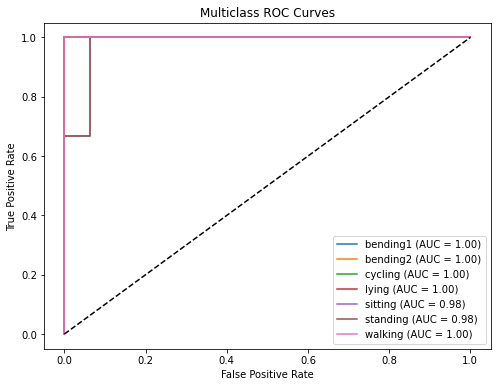

Macro-average AUC: 0.9940476190476192


In [22]:
y_test_binary_multi = label_binarize(y_test_multi, classes=activities)
y_test_prob_multi = multi_model.predict_proba(X_test_multi)

plt.figure(figsize=(8, 6))

for i, activity in enumerate(activities):
    fpr, tpr, thresholds = roc_curve(
        y_test_binary_multi[:, i],
        y_test_prob_multi[:, i]
    )
    auc_value = roc_auc_score(
        y_test_binary_multi[:, i],
        y_test_prob_multi[:, i]
    )
    plt.plot(fpr, tpr, label=f"{activity} (AUC = {auc_value:.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves")
plt.legend()
plt.show()

print("Macro-average AUC:",
      roc_auc_score(
          y_test_binary_multi,
          y_test_prob_multi,
          average="macro"
      ))

#### ii. Naive Bayes

In [23]:
l_values = range(1, 21)
best_gaussian_accuracy = 0

for l in l_values:
    X = []

    for activity, filename in train_data:
        features = extract_segment_features(activity, filename, l)
        X.append(features)

    X = np.array(X)

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("naive_bayes", GaussianNB())
    ])

    scores = cross_val_score(
        model, X, y_train_multi, cv=cv, scoring="accuracy"
    )

    mean_accuracy = np.mean(scores)

    if mean_accuracy > best_gaussian_accuracy:
        best_gaussian_accuracy = mean_accuracy
        best_l_gaussian = l

print("Gaussian NB best l:", best_l_gaussian)
print("Gaussian NB 5-fold CV accuracy:", best_gaussian_accuracy)

Gaussian NB best l: 1
Gaussian NB 5-fold CV accuracy: 0.8703296703296705


In [24]:
best_multinomial_accuracy = 0

for l in l_values:
    X = []

    for activity, filename in train_data:
        features = extract_segment_features(activity, filename, l)
        X.append(features)

    X = np.array(X)

    model = Pipeline([
        ("scaler", MinMaxScaler()),
        ("naive_bayes", MultinomialNB())
    ])

    scores = cross_val_score(
        model, X, y_train_multi, cv=cv, scoring="accuracy"
    )

    mean_accuracy = np.mean(scores)

    if mean_accuracy > best_multinomial_accuracy:
        best_multinomial_accuracy = mean_accuracy
        best_l_multinomial = l

print("Multinomial NB best l:", best_l_multinomial)
print("Multinomial NB 5-fold CV accuracy:", best_multinomial_accuracy)

Multinomial NB best l: 5
Multinomial NB 5-fold CV accuracy: 0.7835164835164835


In [25]:
X_train_gaussian = []
X_test_gaussian = []
X_train_multinomial = []
X_test_multinomial = []

for activity, filename in train_data:
    X_train_gaussian.append(
        extract_segment_features(activity, filename, best_l_gaussian)
    )
    X_train_multinomial.append(
        extract_segment_features(activity, filename, best_l_multinomial)
    )

for activity, filename in test_data:
    X_test_gaussian.append(
        extract_segment_features(activity, filename, best_l_gaussian)
    )
    X_test_multinomial.append(
        extract_segment_features(activity, filename, best_l_multinomial)
    )

X_train_gaussian = np.array(X_train_gaussian)
X_test_gaussian = np.array(X_test_gaussian)
X_train_multinomial = np.array(X_train_multinomial)
X_test_multinomial = np.array(X_test_multinomial)

gaussian_model = Pipeline([
    ("scaler", StandardScaler()),
    ("naive_bayes", GaussianNB())
])

multinomial_model = Pipeline([
    ("scaler", MinMaxScaler()),
    ("naive_bayes", MultinomialNB())
])

gaussian_model.fit(X_train_gaussian, y_train_multi)
multinomial_model.fit(X_train_multinomial, y_train_multi)

gaussian_predictions = gaussian_model.predict(X_test_gaussian)
multinomial_predictions = multinomial_model.predict(X_test_multinomial)

print("Gaussian NB test accuracy:", accuracy_score(y_test_multi, gaussian_predictions))
print("Gaussian NB test error:", 1 - accuracy_score(y_test_multi, gaussian_predictions))
print("Gaussian NB confusion matrix:")
print(confusion_matrix(y_test_multi, gaussian_predictions, labels=activities))

print("Multinomial NB test accuracy:", accuracy_score(y_test_multi, multinomial_predictions))
print("Multinomial NB test error:", 1 - accuracy_score(y_test_multi, multinomial_predictions))
print("Multinomial NB confusion matrix:")
print(confusion_matrix(y_test_multi, multinomial_predictions, labels=activities))

Gaussian NB test accuracy: 0.8947368421052632
Gaussian NB test error: 0.10526315789473684
Gaussian NB confusion matrix:
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 2 1 0 0]
 [0 0 0 0 3 0 0]
 [0 0 0 0 1 2 0]
 [0 0 0 0 0 0 3]]
Multinomial NB test accuracy: 0.7894736842105263
Multinomial NB test error: 0.21052631578947367
Multinomial NB confusion matrix:
[[2 0 0 0 0 0 0]
 [0 1 0 0 1 0 0]
 [0 0 3 0 0 0 0]
 [0 1 0 2 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 0 1 2 0]
 [0 0 0 0 0 0 3]]


#### ii. Comparison

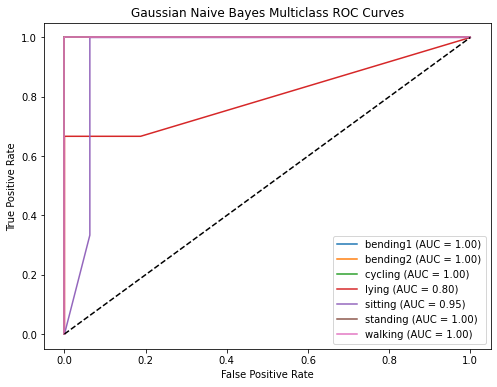

Gaussian NB Macro-average AUC: 0.9642857142857143


In [26]:
gaussian_probabilities = gaussian_model.predict_proba(X_test_gaussian)
multinomial_probabilities = multinomial_model.predict_proba(X_test_multinomial)

y_test_binary_multi = label_binarize(y_test_multi, classes=activities)

plt.figure(figsize=(8, 6))

for i, activity in enumerate(activities):
    fpr, tpr, thresholds = roc_curve(
        y_test_binary_multi[:, i],
        gaussian_probabilities[:, i]
    )
    auc_value = roc_auc_score(
        y_test_binary_multi[:, i],
        gaussian_probabilities[:, i]
    )
    plt.plot(fpr, tpr, label=f"{activity} (AUC = {auc_value:.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gaussian Naive Bayes Multiclass ROC Curves")
plt.legend()
plt.show()

print("Gaussian NB Macro-average AUC:",
      roc_auc_score(
          y_test_binary_multi,
          gaussian_probabilities,
          average="macro"
      ))

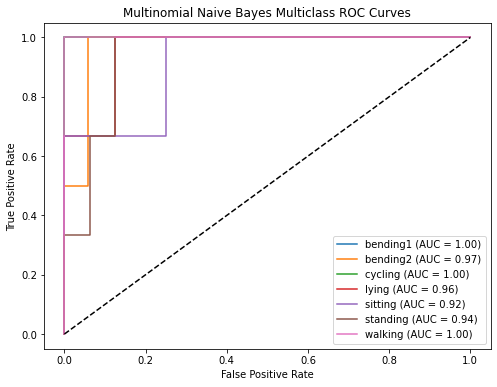

Multinomial NB Macro-average AUC: 0.9690126050420168


In [27]:
plt.figure(figsize=(8, 6))

for i, activity in enumerate(activities):
    fpr, tpr, thresholds = roc_curve(
        y_test_binary_multi[:, i],
        multinomial_probabilities[:, i]
    )
    auc_value = roc_auc_score(
        y_test_binary_multi[:, i],
        multinomial_probabilities[:, i]
    )
    plt.plot(fpr, tpr, label=f"{activity} (AUC = {auc_value:.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multinomial Naive Bayes Multiclass ROC Curves")
plt.legend()
plt.show()

print("Multinomial NB Macro-average AUC:",
      roc_auc_score(
          y_test_binary_multi,
          multinomial_probabilities,
          average="macro"
      ))

For Gaussian Naive Bayes, the best value was (l=1), with a 5-fold cross-validation accuracy of 87.03% and a test accuracy of 89.47%. For Multinomial Naive Bayes, the best value was (l=5), with a cross-validation accuracy of 78.35% and a test accuracy of 78.95%.

Gaussian Naive Bayes performed better than Multinomial Naive Bayes on both the cross-validation and test sets. Its test error was 10.53%, while Multinomial Naive Bayes had a test error of 21.05%. Gaussian Naive Bayes correctly classified 17 of the 19 test instances, while Multinomial Naive Bayes correctly classified 15. However, Multinomial Naive Bayes had a slightly higher macro-average AUC of 0.9690, compared with 0.9643 for Gaussian Naive Bayes.

iii. L1-penalized multinomial logistic regression and Gaussian Naive Bayes performed equally well on the test set, both achieving an accuracy of 89.47% and a test error of 10.53%. L1-penalized multinomial logistic regression had a higher 5-fold cross-validation accuracy of 89.78%, compared with 87.03% for Gaussian Naive Bayes. Multinomial Naive Bayes performed worse, with a test accuracy of 78.95%. Although Multinomial Naive Bayes had a higher macro-average AUC than Gaussian Naive Bayes, its lower test and cross-validation accuracies suggest that it was less suitable for this problem. Overall, L1-penalized multinomial logistic regression was slightly better in this problem because it had the highest cross-validation accuracy while matching Gaussian Naive Bayes on test accuracy.

## 3. ISLR 4.8.3

The Bayes classifier assigns an observation (X=x) to the class with the largest posterior probability:

$$
P(Y=k\mid X=x)=\frac{\pi_k f_k(x)}{\sum_{j=1}^{K}\pi_j f_j(x)}
$$

Substituting the normal density:

$$
P(Y=k\mid X=x)=
\frac{\frac{\pi_k}{\sigma_k}e^{-\frac{(x-\mu_k)^2}{2\sigma_k^2}}}
{\sum_{j=1}^{K}\frac{\pi_j}{\sigma_j}e^{-\frac{(x-\mu_j)^2}{2\sigma_j^2}}}
$$


$$
\delta_k(x)=\log(\pi_k)-\log(\sigma_k)-\frac{(x-\mu_k)^2}{2\sigma_k^2}+C
$$


$$
\delta_k(x)=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k}{\sigma_k^2}x-\frac{\mu_k^2}{2\sigma_k^2}+\log(\pi_k)-\log(\sigma_k)+C
$$

Since the variances can differ across classes, the (x^2) terms generally do not cancel out. Thus, the decision boundary is quadratic rather than linear.

## 4. ISLR 4.8.7

Given:

$$
P(Yes)=0.8,\quad P(No)=0.2
$$

$$
X\mid Yes\sim N(10,36),\quad X\mid No\sim N(0,36)
$$

Using Bayes' theorem:

$$
P(Yes\mid X=4)=
\frac{f_{Yes}(4)P(Yes)}
{f_{Yes}(4)P(Yes)+f_{No}(4)P(No)}
$$

Using the normal dzensity:

$$
f(x)=\frac{1}{\sqrt{2\pi\sigma^2}}
e^{-\frac{(x-\mu)^2}{2\sigma^2}}
$$



$$
f_{Yes}(4)=
\frac{1}{\sqrt{2\pi(36)}}
e^{-\frac{(4-10)^2}{2(36)}}
\approx 0.0403
$$



$$
f_{No}(4)=
\frac{1}{\sqrt{2\pi(36)}}
e^{-\frac{(4-0)^2}{2(36)}}
\approx 0.0532
$$


$$
P(Yes\mid X=4)=
\frac{0.0403(0.8)}
{0.0403(0.8)+0.0532(0.2)}
\approx 0.752
$$

The posterior probability that the observation belongs to the Yes class is approximately 75.2%.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9